<a href="https://colab.research.google.com/github/KadeejaHibaPT/CI-lab/blob/main/CIexp_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PART 1: INITIAL FITNESS, PERSONAL BEST AND GLOBAL BEST


,Particle,Initial Position,Initial Velocity,Initial Fitness,Initial pbest
0,P1,"(-3.0, -10.0)","(-8.0, -2.0)",1145.0,"(-3.0, -10.0)"
1,P2,"(2.0, 2.0)","(2.0, 4.0)",10.0,"(2.0, 2.0)"
2,P3,"(1.0, -3.0)","(1.0, -3.0)",277.0,"(1.0, -3.0)"
3,P4,"(5.0, 10.0)","(-1.0, 0.0)",337.0,"(5.0, 10.0)"


Initial global-best particle: P2
Initial global-best position: [2. 2.]
Initial global-best fitness: 10.0

PART 2: RESULTS OF ONE PSO ITERATION


,Particle,"r1 (x, y)","r2 (x, y)",Updated Velocity,Updated Position,Fitness,Personal Best
0,P1,"(0.77396, 0.43888)","(0.8586, 0.69737)","(4.58598, 15.73683)","(1.58598, 5.73683)",99.583765,"(1.58598, 5.73683)"
1,P2,"(0.09418, 0.97562)","(0.76114, 0.78606)","(1.0, 2.0)","(3.0, 4.0)",17.000000,"(2.0, 2.0)"
2,P3,"(0.12811, 0.45039)","(0.3708, 0.92676)","(1.2416, 7.76765)","(2.2416, 4.76765)",25.018047,"(2.2416, 4.76765)"
3,P4,"(0.64387, 0.82276)","(0.44341, 0.22724)","(-3.16049, -3.63582)","(1.83951, 6.36418)",123.539209,"(1.83951, 6.36418)"


Updated global-best position: [2. 2.]
Updated global-best fitness: 10.0

PART 3: COMPLETE PSO OPTIMIZATION
Final x: 1.9998684290004018
Final y: 2.9999661137653226
Final fitness: 3.6400394354242416e-07
Number of iterations: 82
Stopping criterion achieved: True


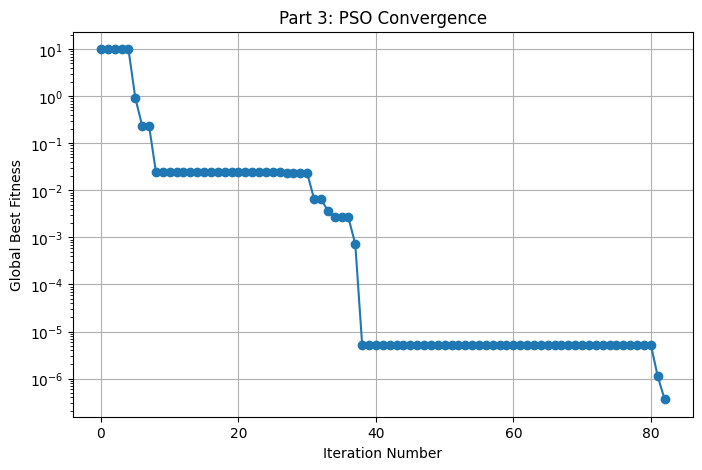


Verification of simultaneous equations
Equation 1 (4x - 3y + 1): -0.00042462529436004814
Equation 2 (3x + y - 9): -0.0004285992334711608
Calculated fitness: 3.6400394354242416e-07

PART 4: PARAMETER STUDY - 36 COMBINATIONS


,Omega,C1,C2,Iterations,Final X,Final Y,Final Fitness,Success (F < 1e-6)
0,0.2,1,1,100,2.263464,3.209051,1.180964e+00,False
1,0.2,1,2,23,1.999908,2.999862,1.700000e-07,True
2,0.2,1,3,96,1.999814,2.999720,7.100000e-07,True
3,0.2,2,1,100,2.134414,3.356344,8.593307e-01,False
4,0.2,2,2,49,2.000153,3.000223,4.700000e-07,True
5,0.2,2,3,100,2.054225,3.045706,4.978764e-02,False
6,0.2,3,1,100,2.068314,3.089621,8.678751e-02,False
7,0.2,3,2,100,1.947667,2.950554,4.634034e-02,False
8,0.2,3,3,100,2.000709,3.001477,1.553000e-05,False
9,0.5,1,1,100,1.999770,2.999247,3.870000e-06,False


Number of successful combinations: 10
Number of unsuccessful combinations: 26

Fastest successful parameter combination:


,Value
Omega,0.2
C1,1
C2,2
Iterations,23
Final X,1.999908
Final Y,2.999862
Final Fitness,0.0
Success (F < 1e-6),True



Parameter study observations:
High inertia weight can encourage exploration.
Low inertia weight can reduce momentum and help convergence.
High c1 increases the influence of personal best.
High c2 increases the influence of global best.

PART 5: VELOCITY CLAMPING


,Method,Iterations,Final X,Final Y,Final Fitness,Success (F < 1e-6)
0,Without Clamping,82,1.999868,2.999966,3.600000e-07,True
1,"With Clamping [-4, 4]",63,1.999880,2.999770,3.900000e-07,True


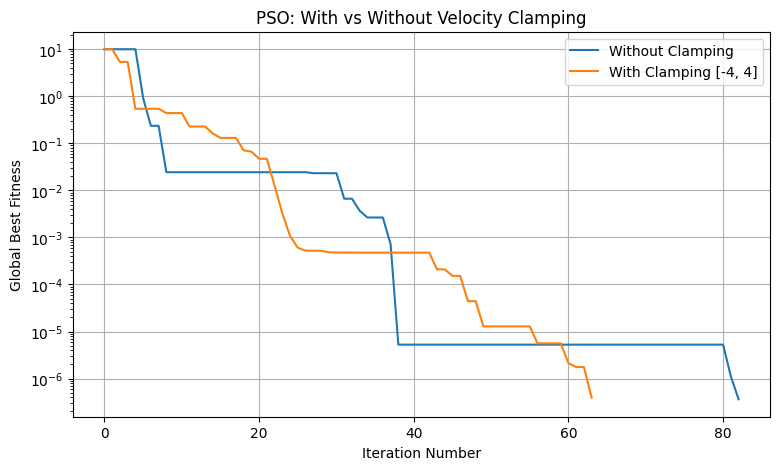

Velocity clamping limits each velocity component to [-4, 4].
Compare the iteration counts and final fitness values above.

FINAL OBSERVATIONS AND CONCLUSION
1. PSO minimizes the fitness function of the two equations.
2. Each particle updates its velocity and position.
3. Personal best and global best guide particle movement.
4. The parameter study compares 36 combinations.
5. Velocity clamping restricts excessively large velocity components.
6. The exact solution is x = 2 and y = 3.
7. The exact minimum fitness is 0.

Exact solution verification:
4(2) - 3(3) + 1 = 0
3(2) + 3 - 9 = 0
F(2, 3) = 0


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ============================================================
# PART 1: PROBLEM DEFINITION AND INITIAL FITNESS
# ============================================================

def fitness(position):
    x, y = position
    return (4*x - 3*y + 1)**2 + (3*x + y - 9)**2

initial_positions = np.array([
    [-3, -10],
    [2, 2],
    [1, -3],
    [5, 10]
], dtype=float)

initial_velocities = np.array([
    [-8, -2],
    [2, 4],
    [1, -3],
    [-1, 0]
], dtype=float)

particle_names = ["P1", "P2", "P3", "P4"]

initial_fitness = np.array([
    fitness(p) for p in initial_positions
])

pbest = initial_positions.copy()
pbest_fitness = initial_fitness.copy()

gbest_index = np.argmin(pbest_fitness)
gbest = pbest[gbest_index].copy()
gbest_fitness = pbest_fitness[gbest_index]

print("=" * 65)
print("PART 1: INITIAL FITNESS, PERSONAL BEST AND GLOBAL BEST")
print("=" * 65)

initial_table = pd.DataFrame({
    "Particle": particle_names,
    "Initial Position": [tuple(p) for p in initial_positions],
    "Initial Velocity": [tuple(v) for v in initial_velocities],
    "Initial Fitness": initial_fitness,
    "Initial pbest": [tuple(p) for p in pbest]
})

display(initial_table)

print("Initial global-best particle:", particle_names[gbest_index])
print("Initial global-best position:", gbest)
print("Initial global-best fitness:", gbest_fitness)


# ============================================================
# PART 2: ONE COMPLETE PSO ITERATION WITH DETAILED OUTPUT
# ============================================================

omega = 0.5
c1 = 2
c2 = 2

positions = initial_positions.copy()
velocities = initial_velocities.copy()
pbest = positions.copy()
pbest_fitness = np.array([fitness(p) for p in positions])

gbest_index = np.argmin(pbest_fitness)
gbest = pbest[gbest_index].copy()
gbest_fitness = pbest_fitness[gbest_index]

rng = np.random.default_rng(42)
iteration_results = []

for i in range(4):

    r1 = rng.random(2)
    r2 = rng.random(2)

    old_position = positions[i].copy()

    new_velocity = (
        omega * velocities[i]
        + c1 * r1 * (pbest[i] - old_position)
        + c2 * r2 * (gbest - old_position)
    )

    new_position = old_position + new_velocity
    new_position = np.clip(new_position, -10, 10)

    new_fitness = fitness(new_position)

    if new_fitness < pbest_fitness[i]:
        pbest[i] = new_position.copy()
        pbest_fitness[i] = new_fitness

    if new_fitness < gbest_fitness:
        gbest = new_position.copy()
        gbest_fitness = new_fitness

    positions[i] = new_position
    velocities[i] = new_velocity

    iteration_results.append({
        "Particle": particle_names[i],
        "r1 (x, y)": tuple(np.round(r1, 5)),
        "r2 (x, y)": tuple(np.round(r2, 5)),
        "Updated Velocity": tuple(np.round(new_velocity, 5)),
        "Updated Position": tuple(np.round(new_position, 5)),
        "Fitness": new_fitness,
        "Personal Best": tuple(np.round(pbest[i], 5))
    })

print("\n" + "=" * 65)
print("PART 2: RESULTS OF ONE PSO ITERATION")
print("=" * 65)

display(pd.DataFrame(iteration_results))

print("Updated global-best position:", gbest)
print("Updated global-best fitness:", gbest_fitness)


# ============================================================
# COMMON PSO FUNCTION FOR PARTS 3, 4 AND 5
# ============================================================

def run_pso(omega=0.5, c1=2, c2=2,
            max_iter=100, seed=42, clamp=None):

    rng = np.random.default_rng(seed)

    positions = initial_positions.copy()
    velocities = initial_velocities.copy()

    pbest = positions.copy()
    pbest_fitness = np.array([fitness(p) for p in positions])

    gbest_index = np.argmin(pbest_fitness)
    gbest = pbest[gbest_index].copy()
    gbest_fitness = pbest_fitness[gbest_index]

    history = [gbest_fitness]
    iterations = 0

    if gbest_fitness < 1e-6:
        return gbest, gbest_fitness, iterations, history

    for iteration in range(max_iter):

        for i in range(len(positions)):

            r1 = rng.random(2)
            r2 = rng.random(2)

            velocities[i] = (
                omega * velocities[i]
                + c1 * r1 * (pbest[i] - positions[i])
                + c2 * r2 * (gbest - positions[i])
            )

            if clamp is not None:
                velocities[i] = np.clip(
                    velocities[i], -clamp, clamp
                )

            positions[i] = positions[i] + velocities[i]
            positions[i] = np.clip(positions[i], -10, 10)

            current_fitness = fitness(positions[i])

            if current_fitness < pbest_fitness[i]:
                pbest[i] = positions[i].copy()
                pbest_fitness[i] = current_fitness

            if current_fitness < gbest_fitness:
                gbest = positions[i].copy()
                gbest_fitness = current_fitness

        history.append(gbest_fitness)
        iterations = iteration + 1

        if gbest_fitness < 1e-6:
            break

    return gbest, gbest_fitness, iterations, history


# ============================================================
# PART 3: COMPLETE PSO OPTIMIZATION
# ============================================================

print("\n" + "=" * 65)
print("PART 3: COMPLETE PSO OPTIMIZATION")
print("=" * 65)

final_position, final_fitness, iterations, history = run_pso(
    omega=0.5,
    c1=2,
    c2=2,
    max_iter=100,
    seed=42
)

print("Final x:", final_position[0])
print("Final y:", final_position[1])
print("Final fitness:", final_fitness)
print("Number of iterations:", iterations)
print("Stopping criterion achieved:", final_fitness < 1e-6)

plt.figure(figsize=(8, 5))
plt.plot(range(len(history)), history, marker="o")
plt.xlabel("Iteration Number")
plt.ylabel("Global Best Fitness")
plt.title("Part 3: PSO Convergence")
plt.yscale("log")
plt.grid(True)
plt.show()


# ============================================================
# VERIFICATION OF THE FINAL SOLUTION
# ============================================================

x, y = final_position

eq1 = 4*x - 3*y + 1
eq2 = 3*x + y - 9

print("\nVerification of simultaneous equations")
print("Equation 1 (4x - 3y + 1):", eq1)
print("Equation 2 (3x + y - 9):", eq2)
print("Calculated fitness:", fitness(final_position))


# ============================================================
# PART 4: EFFECT OF PSO PARAMETERS
# ============================================================

print("\n" + "=" * 65)
print("PART 4: PARAMETER STUDY - 36 COMBINATIONS")
print("=" * 65)

parameter_results = []

for omega_value in [0.2, 0.5, 0.7, 0.9]:
    for c1_value in [1, 2, 3]:
        for c2_value in [1, 2, 3]:

            position, fit, count, curve = run_pso(
                omega=omega_value,
                c1=c1_value,
                c2=c2_value,
                max_iter=100,
                seed=42
            )

            parameter_results.append({
                "Omega": omega_value,
                "C1": c1_value,
                "C2": c2_value,
                "Iterations": count,
                "Final X": position[0],
                "Final Y": position[1],
                "Final Fitness": fit,
                "Success (F < 1e-6)": fit < 1e-6
            })

parameter_table = pd.DataFrame(parameter_results)

display(parameter_table.round(8))

successful_runs = parameter_table[
    parameter_table["Success (F < 1e-6)"]
].sort_values("Iterations")

print("Number of successful combinations:", len(successful_runs))
print("Number of unsuccessful combinations:", 36 - len(successful_runs))

if len(successful_runs) > 0:
    fastest = successful_runs.iloc[0]
    print("\nFastest successful parameter combination:")
    display(fastest.to_frame("Value"))

    fastest_iterations = fastest["Iterations"]
    tied = successful_runs[
        successful_runs["Iterations"] == fastest_iterations
    ]
    if len(tied) > 1:
        print("Note: Multiple combinations share the minimum iteration count.")
        display(tied[["Omega", "C1", "C2", "Iterations"]])
else:
    print("No combination achieved the stopping criterion within 100 iterations.")

print("\nParameter study observations:")
print("High inertia weight can encourage exploration.")
print("Low inertia weight can reduce momentum and help convergence.")
print("High c1 increases the influence of personal best.")
print("High c2 increases the influence of global best.")


# ============================================================
# PART 5: VELOCITY CLAMPING COMPARISON
# ============================================================

print("\n" + "=" * 65)
print("PART 5: VELOCITY CLAMPING")
print("=" * 65)

position_a, fitness_a, iterations_a, history_a = run_pso(
    omega=0.5,
    c1=2,
    c2=2,
    max_iter=100,
    seed=42,
    clamp=None
)

position_b, fitness_b, iterations_b, history_b = run_pso(
    omega=0.5,
    c1=2,
    c2=2,
    max_iter=100,
    seed=42,
    clamp=4
)

comparison_table = pd.DataFrame({
    "Method": [
        "Without Clamping",
        "With Clamping [-4, 4]"
    ],
    "Iterations": [iterations_a, iterations_b],
    "Final X": [position_a[0], position_b[0]],
    "Final Y": [position_a[1], position_b[1]],
    "Final Fitness": [fitness_a, fitness_b],
    "Success (F < 1e-6)": [
        fitness_a < 1e-6,
        fitness_b < 1e-6
    ]
})

display(comparison_table.round(8))

plt.figure(figsize=(9, 5))
plt.plot(
    range(len(history_a)),
    history_a,
    label="Without Clamping"
)
plt.plot(
    range(len(history_b)),
    history_b,
    label="With Clamping [-4, 4]"
)

plt.xlabel("Iteration Number")
plt.ylabel("Global Best Fitness")
plt.title("PSO: With vs Without Velocity Clamping")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()

print("Velocity clamping limits each velocity component to [-4, 4].")
print("Compare the iteration counts and final fitness values above.")


# ============================================================
# FINAL OBSERVATIONS AND CONCLUSION
# ============================================================

print("\n" + "=" * 65)
print("FINAL OBSERVATIONS AND CONCLUSION")
print("=" * 65)

print("1. PSO minimizes the fitness function of the two equations.")
print("2. Each particle updates its velocity and position.")
print("3. Personal best and global best guide particle movement.")
print("4. The parameter study compares 36 combinations.")
print("5. Velocity clamping restricts excessively large velocity components.")
print("6. The exact solution is x = 2 and y = 3.")
print("7. The exact minimum fitness is 0.")

print("\nExact solution verification:")
print("4(2) - 3(3) + 1 =", 4*2 - 3*3 + 1)
print("3(2) + 3 - 9 =", 3*2 + 3 - 9)
print("F(2, 3) =", fitness([2, 3]))
